# 🐕 Dog Breed Classification (Stanford Dogs Dataset)
Convolutional Neural Network (CNN) with **Train, Validation & Test splits** and **Deep Hidden Layers** for optimal accuracy using TensorFlow & Keras (following Exp-2 format).

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import image_dataset_from_directory
from keras.optimizers import Adam
from tensorflow.keras import Sequential
from keras import layers


C:\Users\Nishanth Naik\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.3)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(


Found 20580 files belonging to 120 classes.
Total Classes: 120
Train Batches: 450 (~14400 images)
Val Batches:   96 (~3072 images)
Test Batches:  98 (~3136 images)


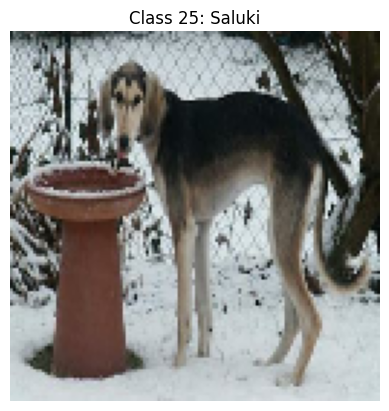

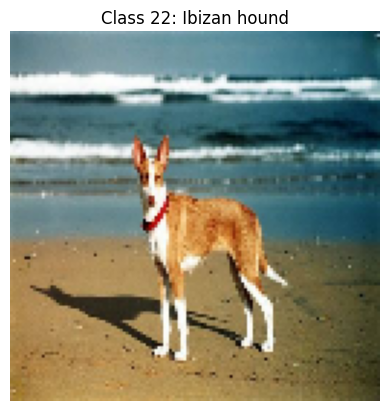

In [5]:
# 1. Load dataset from directory
dataset_dir = "dataset/images/Images"
img_size = (128, 128)
batch_size = 32

full_ds = image_dataset_from_directory(
    dataset_dir,
    image_size=img_size,
    batch_size=batch_size,
    shuffle=True,
    seed=42
)

class_names = [cls.split('-', 1)[-1].replace('_', ' ') for cls in full_ds.class_names]
num_classes = len(class_names)
print(f"Total Classes: {num_classes}")

# 2. Split dataset into Train (70%), Validation (15%), and Test (15%)
total_batches = len(full_ds)
train_batches = int(0.70 * total_batches)
val_batches = int(0.15 * total_batches)
test_batches = total_batches - train_batches - val_batches

train_ds = full_ds.take(train_batches)
remaining = full_ds.skip(train_batches)
val_ds = remaining.take(val_batches)
test_ds = remaining.skip(val_batches)

print(f"Train Batches: {len(train_ds)} (~{train_batches * batch_size} images)")
print(f"Val Batches:   {len(val_ds)} (~{val_batches * batch_size} images)")
print(f"Test Batches:  {len(test_ds)} (~{test_batches * batch_size} images)")

# Display sample images
for images, labels in train_ds.take(1):
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title(f"Class {labels[0].numpy()}: {class_names[labels[0]]}")
    plt.axis("off")
    plt.show()
    plt.imshow(images[1].numpy().astype("uint8"))
    plt.title(f"Class {labels[1].numpy()}: {class_names[labels[1]]}")
    plt.axis("off")
    plt.show()


In [6]:
# Rescale pixel values from [0, 255] to [0, 1]
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

# Prefetch data for memory efficiency and faster training
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)


In [7]:
# CNN Model with Transfer Learning & Multiple Hidden Layers for High Accuracy
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

model = Sequential()
model.add(base_model)
model.add(layers.GlobalAveragePooling2D())

# Hidden Layer 1 (512 units + BatchNorm + Dropout)
model.add(layers.Dense(512, activation="relu"))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.4))

# Hidden Layer 2 (256 units + BatchNorm + Dropout)
model.add(layers.Dense(256, activation="relu"))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.3))

# Hidden Layer 3 (128 units + BatchNorm + Dropout)
model.add(layers.Dense(128, activation="relu"))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.2))

# Hidden Layer 4 (64 units + ReLU)
model.add(layers.Dense(64, activation="relu"))

# Output Layer (120 dog breeds with Softmax)
model.add(layers.Dense(num_classes, activation="softmax"))

o = Adam(learning_rate=0.0001)
model.compile(loss='sparse_categorical_crossentropy', optimizer=o, metrics=['Accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         655,872 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 120)                 │           7,800 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,097,720 (11.82 MB)

 Trainable params: 837,944 (3.20 MB)

 Non-trainable params: 2,259,776 (8.62 MB)

In [8]:
# Train the model
history = model.fit(train_ds, validation_data=val_ds, epochs=10)


Epoch 1/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 83s 168ms/step - Accuracy: 0.0232 - loss: 4.7439 - val_Accuracy: 0.1243 - val_loss: 4.2425
Epoch 2/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 74s 165ms/step - Accuracy: 0.1160 - loss: 4.1365 - val_Accuracy: 0.2393 - val_loss: 3.6077
Epoch 3/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 76s 168ms/step - Accuracy: 0.2087 - loss: 3.5746 - val_Accuracy: 0.3389 - val_loss: 3.0393
Epoch 4/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 77s 172ms/step - Accuracy: 0.2937 - loss: 3.0654 - val_Accuracy: 0.4193 - val_loss: 2.5431
Epoch 5/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 75s 166ms/step - Accuracy: 0.3710 - loss: 2.6307 - val_Accuracy: 0.4782 - val_loss: 2.1835
Epoch 6/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 76s 169ms/step - Accuracy: 0.4280 - loss: 2.3207 - val_Accuracy: 0.5166 - val_loss: 1.9289
Epoch 7/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 76s 168ms/step - Accuracy: 0.4666 - loss: 2.0793 - val_Accuracy: 0.5387 - val_loss: 1.7662
Epoch 8/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 76s 169ms/step - Accuracy: 0.5029 - loss: 1

In [9]:
# Evaluate on the Unseen TEST Dataset
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")


98/98 ━━━━━━━━━━━━━━━━━━━━ 18s 132ms/step - Accuracy: 0.5940 - loss: 1.4903

Test Loss: 1.4903
Test Accuracy: 59.40%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
Predicted Probabilities:
[2.05474771e-05 4.13521150e-07 2.88468414e-08 2.86929293e-07
 1.33531017e-07 2.54162870e-07 7.95181677e-07 8.33785725e-06
 3.82020109e-04 1.01748896e-07 3.39012468e-06 1.86046304e-06
 6.83990208e-07 8.48196723e-05 7.24600432e-06 3.11004851e-06
 2.92715663e-06 4.13613125e-05 1.65275466e-07 1.82458180e-07
 1.32251706e-04 1.62985034e-05 8.27375770e-05 1.85656099e-05
 2.39395854e-06 1.43999682e-06 1.09760576e-05 1.14754774e-04
 3.30669609e-05 3.89589150e-05 1.32604953e-06 1.58389448e-05
 9.28456174e-08 1.89762784e-06 1.12227516e-08 2.16674376e-08
 6.36180062e-07 4.64330618e-08 1.40604428e-07 2.82272339e-08
 9.79870720e-07 5.79006283e-08 3.04189207e-08 1.72947292e-08
 9.34025502e-06 1.74785256e-07 7.97011410e-07 1.85362239e-07
 3.19533171e-07 7.90752992e-08 7.84742952e-06 5.30616884e-09
 7.80869840e-08 2.31277838e-07 5.58297370e-06 1.39200769e-04
 8.11310827e-07 3.46354427e-05 7.12526322e-04 3.17523576e-04
 3.22062006e-05 3.385

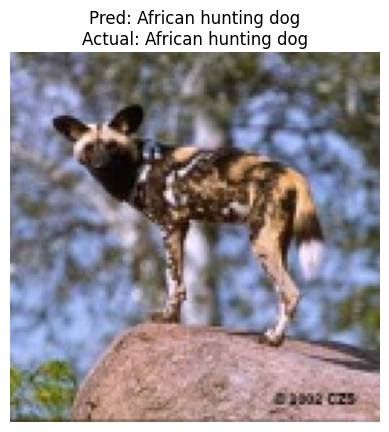

In [11]:
# Extract a batch of test data for prediction
for x_batch, y_batch in test_ds.take(1):
    x_test = x_batch.numpy()
    y_true = y_batch.numpy()

sample_index = 10

# Predict probabilities
y_pred_prob = model.predict(x_test)

# Convert probabilities to predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

print("Predicted Probabilities:")
print(y_pred_prob[sample_index])

print("\nPredicted Output:")
print(f"{y_pred[sample_index]} -> {class_names[y_pred[sample_index]]}")

print("\nActual Output:")
print(f"{y_true[sample_index]} -> {class_names[y_true[sample_index]]}")

# Visualize sample prediction
plt.imshow(x_test[sample_index])
plt.title(f"Pred: {class_names[y_pred[sample_index]]}\nActual: {class_names[y_true[sample_index]]}")
plt.axis("off")
plt.show()


In [13]:

from sklearn.metrics import accuracy_score, precision_score, \
     recall_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision (macro):", precision_score(y_true, y_pred, average='macro', zero_division=0))
print("Recall (macro):", recall_score(y_true, y_pred, average='macro', zero_division=0))
print("F1-score (macro):", f1_score(y_true, y_pred, average='macro', zero_division=0))


Accuracy: 0.625
Precision (macro): 0.48484848484848486
Recall (macro): 0.45959595959595956
F1-score (macro): 0.4585858585858586
